In [5]:
# TAREA 4
# Actividad 1.
# Analisis de sentimientos en opiniones de clientes en espanol
# Preparacion del entorno, autenticacion y carga de recursos

# Configuración Y verificación de GPU
# nvidia-smi muestra informacion de la GPU asignada por Colab.
import subprocess
import sys

print("=" * 65)
print("1. CONFIGURACION Y VERIFICACION DE GPU")
print("=" * 65)

gpu_info = subprocess.run(
    ["nvidia-smi"],
    capture_output=True,
    text=True
)

if gpu_info.returncode == 0:
    print(gpu_info.stdout)
else:
    print("No se detecto una GPU NVIDIA activa.")

# Instalación de dependencias
print("=" * 65)
print("2. INSTALACION DE DEPENDENCIAS")
print("=" * 65)

# Instalación de las bibliotecas necesarias para cargar modelos,
# procesar datos y evaluar posteriormente las predicciones.
# PyTorch se conserva desde la instalacion de Google Colab.
paquetes = [
    "transformers>=4.45,<5",
    "datasets>=3.0,<5",
    "evaluate>=0.4,<1",
    "accelerate>=1.0,<2",
    "huggingface_hub>=0.26,<1",
    "scikit-learn>=1.5,<2",
    "pandas>=2.0,<3",
    "sentencepiece>=0.2,<1",
    "protobuf>=4.25,<7"
]

subprocess.check_call(
    [sys.executable, "-m", "pip", "install", "-q", *paquetes]
)

# Importación de las bibliotecas despues de instalarlas.
import torch
import pandas as pd
import transformers
import datasets
import sklearn
import huggingface_hub
from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)
from huggingface_hub import login

# Verificación de que PyTorch pueda utilizar la GPU.
dispositivo = "cuda:0" if torch.cuda.is_available() else "cpu"

print(f"PyTorch: {torch.__version__}")
print(f"Transformers: {transformers.__version__}")
print(f"Datasets: {datasets.__version__}")
print(f"Dispositivo seleccionado: {dispositivo}")

if dispositivo == "cuda:0":
    print(f"GPU disponible: {torch.cuda.get_device_name(0)}")
else:
    raise RuntimeError(
        "La actividad requiere GPU. Activa una GPU en Colab "
        "y vuelve a ejecutar esta celda."
    )

# Autenticación en Hugging Face Hub
print("\n" + "=" * 65)
print("3. AUTENTICACION EN HUGGING FACE HUB")
print("=" * 65)

# El token se obtiene desde Secrets de Google Colab.
from google.colab import userdata

token_hf = None

try:
    token_hf = userdata.get("HF_TOKEN")
except Exception:
    print("No se encontro HF_TOKEN en Secrets de Colab.")

if token_hf:
    login(token=token_hf, add_to_git_credential=False)
    print("Autenticacion realizada correctamente.")
else:
    print(
        "Se continuara con acceso publico sin autenticacion. "
        "Los recursos seleccionados no requieren token."
    )

# Carga de modelos y dataset
print("\n" + "=" * 65)
print("4. CARGA DE MODELOS Y DATASET")
print("=" * 65)

# Definición de los tres modelos preentrenados que serán comparados.
modelos_hf = {
    "RoBERTuito": (
        "pysentimiento/robertuito-sentiment-analysis"
    ),
    "BETO": (
        "rafaelwt/beto-amazon-reviews-es-3clases"
    ),
    "XLM-RoBERTa": (
        "cardiffnlp/twitter-xlm-roberta-base-sentiment"
    )
}

# Se carga únicamente la particion oficial de prueba.
# Esto evita evaluar BETO con sus datos de entrenamiento.
dataset_id = "SetFit/amazon_reviews_multi_es"
dataset_prueba = load_dataset(dataset_id, split="test")

# El dataset codifica las estrellas de 0 a 4:
# 0-1 = negativo; 2 = neutral; 3-4 = positivo.
def convertir_sentimiento(etiqueta):
    if etiqueta in (0, 1):
        return "NEG"
    elif etiqueta == 2:
        return "NEU"
    elif etiqueta in (3, 4):
        return "POS"
    else:
        raise ValueError(f"Etiqueta no reconocida: {etiqueta}")

# Conversión del dataset a una tabla para facilitar su manejo.
df_original = dataset_prueba.to_pandas()

df_original["sentimiento"] = (
    df_original["label"].apply(convertir_sentimiento)
)

# Selección de 100 opiniones por categoria.
# random_state fija la semilla para reproducir la muestra.
muestras = []

for categoria in ["NEG", "NEU", "POS"]:
    grupo = df_original[
        df_original["sentimiento"] == categoria
    ]

    if len(grupo) < 100:
        raise ValueError(
            f"No hay 100 registros de la categoria {categoria}."
        )

    muestras.append(
        grupo.sample(n=100, random_state=42)
    )

# Se unifican las muestras y se mezcla el orden de los registros.
df_evaluacion = pd.concat(
    muestras, ignore_index=True
).sample(
    frac=1, random_state=42
).reset_index(drop=True)

# Se conservan las columnas necesarias para la evaluacion.
df_evaluacion = df_evaluacion[
    ["id", "text", "label", "sentimiento"]
].copy()

df_evaluacion = df_evaluacion.rename(
    columns={
        "id": "id_resena",
        "text": "comentario",
        "label": "valoracion_original"
    }
)

# Se almacena la muestra para el entregable CSV.
ruta_csv = "/content/dataset_sentimientos_300.csv"

df_evaluacion.to_csv(
    ruta_csv,
    index=False,
    encoding="utf-8-sig"
)

print(f"\nDataset: {dataset_id}")
print(f"Registros seleccionados: {len(df_evaluacion)}")
print("\nDistribucion de sentimientos:")
print(df_evaluacion["sentimiento"].value_counts())
print(f"\nArchivo CSV generado: {ruta_csv}")

# Carga de los tokenizadores y los modelos preentrenados.
# Permanecen inicialmente en CPU para conservar memoria GPU.
# La inferencia posterior los utilizara uno por uno en GPU.
tokenizadores = {}
modelos_cargados = {}

# Estas equivalencias permiten comparar etiquetas distintas.
equivalencias = {
    "NEG": "NEG",
    "NEU": "NEU",
    "POS": "POS",
    "NEGATIVO": "NEG",
    "NEUTRO": "NEU",
    "NEUTRAL": "NEU",
    "POSITIVO": "POS",
    "NEGATIVE": "NEG",
    "POSITIVE": "POS"
}

for nombre, identificador in modelos_hf.items():
    print(f"\nCargando modelo: {nombre}")
    print(f"Repositorio: {identificador}")

    tokenizador = AutoTokenizer.from_pretrained(
        identificador
    )

    modelo = AutoModelForSequenceClassification.from_pretrained(
        identificador
    )

    # Comprobación de que el modelo tiene tres categorias.
    etiquetas = list(modelo.config.id2label.values())

    etiquetas_normalizadas = {
        equivalencias.get(str(e).upper().strip())
        for e in etiquetas
    }

    if etiquetas_normalizadas != {"NEG", "NEU", "POS"}:
        raise ValueError(
            f"Etiquetas incompatibles en {nombre}: {etiquetas}"
        )

    modelo.eval()

    tokenizadores[nombre] = tokenizador
    modelos_cargados[nombre] = modelo

    print(f"Modelo cargado: {nombre}")
    print(f"Etiquetas originales: {etiquetas}")

# Resumen de la celda 1
print("\n" + "=" * 65)
print("RESUMEN DE LA CELDA 1")
print("=" * 65)

print(f"Dispositivo disponible: {dispositivo}")
print(f"Modelos cargados: {len(modelos_cargados)}")
print(f"Opiniones seleccionadas: {len(df_evaluacion)}")
print(f"Dataset exportado: {ruta_csv}")
print("Estado: preparacion finalizada correctamente.")

# Las variables quedan disponibles para las siguientes celdas:
# dispositivo, tokenizadores, modelos_cargados y df_evaluacion.


1. CONFIGURACION Y VERIFICACION DE GPU
Sat Oct 10 19:34:50 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   48C    P8             14W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+--------

Repo card metadata block was not found. Setting CardData to empty.



Dataset: SetFit/amazon_reviews_multi_es
Registros seleccionados: 300

Distribucion de sentimientos:
sentimiento
POS    100
NEU    100
NEG    100
Name: count, dtype: int64

Archivo CSV generado: /content/dataset_sentimientos_300.csv

Cargando modelo: RoBERTuito
Repositorio: pysentimiento/robertuito-sentiment-analysis
Modelo cargado: RoBERTuito
Etiquetas originales: ['NEG', 'NEU', 'POS']

Cargando modelo: BETO
Repositorio: rafaelwt/beto-amazon-reviews-es-3clases
Modelo cargado: BETO
Etiquetas originales: ['negativo', 'neutro', 'positivo']

Cargando modelo: XLM-RoBERTa
Repositorio: cardiffnlp/twitter-xlm-roberta-base-sentiment
Modelo cargado: XLM-RoBERTa
Etiquetas originales: ['negative', 'neutral', 'positive']

RESUMEN DE LA CELDA 1
Dispositivo disponible: cuda:0
Modelos cargados: 3
Opiniones seleccionadas: 300
Dataset exportado: /content/dataset_sentimientos_300.csv
Estado: preparacion finalizada correctamente.


In [6]:
# TAREA 4
# Actividad 1.
# Pipeline de inferencia
# Analisis de sentimientos con tres modelos preentrenados

import time
import gc
import torch
import pandas as pd
from transformers import pipeline

print("=" * 65)
print("CELDA 2. PIPELINE DE INFERENCIA")
print("=" * 65)

# Preparación de datos y resultados
# Recuperamos las opiniones seleccionadas en la celda 1.
textos = df_evaluacion["comentario"].fillna("").astype(str).tolist()

# Diccionarios para conservar predicciones y tiempos.
predicciones_modelos = {}
tiempos_inferencia = {}

# Equivalencias para unificar las etiquetas de sentimiento.
mapa_sentimientos = {
    "NEG": "NEG",
    "NEU": "NEU",
    "POS": "POS",
    "NEGATIVO": "NEG",
    "NEUTRO": "NEU",
    "NEUTRAL": "NEU",
    "POSITIVO": "POS",
    "NEGATIVE": "NEG",
    "POSITIVE": "POS"
}

# Ejecución del pipeline de inferencia
# Procesamiento de los modelos uno por uno para administrar
# la memoria disponible de la GPU.
for nombre, modelo in modelos_cargados.items():

    print(f"\nProcesando modelo: {nombre}")

    tokenizador = tokenizadores[nombre]

    # Creación de un pipeline de clasificacion de textos.
    clasificador = pipeline(
        task="text-classification",
        model=modelo,
        tokenizer=tokenizador,
        device=0
    )

    # Realización de una prediccion inicial para preparar
    # el modelo antes de medir el procesamiento principal.
    _ = clasificador(
        textos[:2],
        truncation=True,
        max_length=128
    )

    # Sincronización de la GPU antes de iniciar la medicion.
    torch.cuda.synchronize()
    inicio = time.perf_counter()

    # Ejecutación de la inferencia sobre las 300 opiniones.
    resultados = clasificador(
        textos,
        batch_size=16,
        truncation=True,
        max_length=128
    )

    # Espera para que terminen las operaciones de GPU.
    torch.cuda.synchronize()
    tiempo_total = time.perf_counter() - inicio

    # Normalización de las etiquetas de salida.
    etiquetas = []

    for resultado in resultados:
        etiqueta_original = resultado["label"].upper().strip()

        etiqueta = mapa_sentimientos.get(etiqueta_original)

        if etiqueta is None:
            raise ValueError(
                f"Etiqueta no reconocida en {nombre}: "
                f"{etiqueta_original}"
            )

        etiquetas.append(etiqueta)

    # Se conservan las etiquetas y las puntuaciones
    # de confianza reportadas por cada modelo.
    predicciones_modelos[nombre] = pd.DataFrame({
        "id_resena": df_evaluacion["id_resena"].values,
        "sentimiento_real": df_evaluacion["sentimiento"].values,
        "sentimiento_predicho": etiquetas,
        "confianza": [r["score"] for r in resultados]
    })

    tiempos_inferencia[nombre] = {
        "tiempo_total_segundos": tiempo_total,
        "tiempo_promedio_segundos": tiempo_total / len(textos)
    }

    print(f"Opiniones procesadas: {len(resultados)}")
    print(f"Tiempo total: {tiempo_total:.3f} segundos")
    print(f"Tiempo promedio: {tiempo_total / len(textos):.5f} s/opinion")

    print("\nDistribucion de predicciones:")
    print(
        predicciones_modelos[nombre][
            "sentimiento_predicho"
        ].value_counts()
    )

    # Se libera la memoria GPU antes del siguiente modelo.
    del clasificador
    modelo.to("cpu")
    gc.collect()
    torch.cuda.empty_cache()

# Verificación de resultados
print("\n" + "=" * 65)
print("RESUMEN DEL PIPELINE DE INFERENCIA")
print("=" * 65)

for nombre, tabla in predicciones_modelos.items():
    print(f"{nombre}: {len(tabla)} predicciones generadas")

    # Comprobación de la existencia de una prediccion por opinion.
    assert len(tabla) == len(df_evaluacion), (
        f"Cantidad incorrecta de predicciones: {nombre}"
    )

print("\nEjemplos de predicciones de los tres modelos:")

# Unificación de las predicciones para visualizar cinco opiniones.
tabla_ejemplos = df_evaluacion[
    ["comentario", "sentimiento"]
].head(5).copy()

for nombre, tabla in predicciones_modelos.items():
    tabla_ejemplos[nombre] = (
        tabla["sentimiento_predicho"].head(5).values
    )

display(tabla_ejemplos)

print("\nPipeline de inferencia finalizado correctamente.")

Device set to use cuda:0


CELDA 2. PIPELINE DE INFERENCIA

Procesando modelo: RoBERTuito
Opiniones procesadas: 300
Tiempo total: 1.604 segundos
Tiempo promedio: 0.00535 s/opinion

Distribucion de predicciones:
sentimiento_predicho
POS    129
NEG    127
NEU     44
Name: count, dtype: int64


Device set to use cuda:0



Procesando modelo: BETO
Opiniones procesadas: 300
Tiempo total: 1.514 segundos
Tiempo promedio: 0.00505 s/opinion

Distribucion de predicciones:
sentimiento_predicho
NEG    122
POS    119
NEU     59
Name: count, dtype: int64


Device set to use cuda:0



Procesando modelo: XLM-RoBERTa
Opiniones procesadas: 300
Tiempo total: 1.517 segundos
Tiempo promedio: 0.00506 s/opinion

Distribucion de predicciones:
sentimiento_predicho
NEG    151
POS    123
NEU     26
Name: count, dtype: int64

RESUMEN DEL PIPELINE DE INFERENCIA
RoBERTuito: 300 predicciones generadas
BETO: 300 predicciones generadas
XLM-RoBERTa: 300 predicciones generadas

Ejemplos de predicciones de los tres modelos:


,comentario,sentimiento,RoBERTuito,BETO,XLM-RoBERTa
0,El tejido parece fuerte y están chulos los det...,POS,NEG,NEU,NEG
1,"Lo tengo ya un mes y lo recargo cada dos días,...",POS,POS,POS,POS
2,Llegaron con funda y un poco rascadas,NEU,NEU,NEU,NEG
3,Todo excepto que es considerablemente más pequ...,NEG,NEU,NEG,NEU
4,"genial, para montarlo en familia y poder disfr...",POS,POS,POS,POS



Pipeline de inferencia finalizado correctamente.


CELDA 3. EVALUACION DEL DESEMPENO DE LOS MODELOS

Resultados Generales (escala de 0 a 1)


,Accuracy,Precision,Recall,F1-score
Modelo,,,,
RoBERTuito,0.6167,0.5911,0.6167,0.5784
BETO,0.7333,0.7298,0.7333,0.7143
XLM-RoBERTa,0.5800,0.5314,0.5800,0.5158



Resultados Expresados En Porcentaje


,Accuracy,Precision,Recall,F1-score
Modelo,,,,
RoBERTuito,61.67,59.11,61.67,57.84
BETO,73.33,72.98,73.33,71.43
XLM-RoBERTa,58.00,53.14,58.00,51.58



Métricas Por Categoría De Sentimiento

Modelo: RoBERTuito


...


Modelo: BETO


,Sentimiento,Precision,Recall,F1-score,Registros
0,Negativo,0.7213,0.88,0.7928,100.0
1,Neutral,0.7119,0.42,0.5283,100.0
2,Positivo,0.7563,0.90,0.8219,100.0



Modelo: XLM-RoBERTa


,Sentimiento,Precision,Recall,F1-score,Registros
0,Negativo,0.5430,0.82,0.6534,100.0
1,Neutral,0.3846,0.10,0.1587,100.0
2,Positivo,0.6667,0.82,0.7354,100.0



Gráfico comparativo de métricas generales


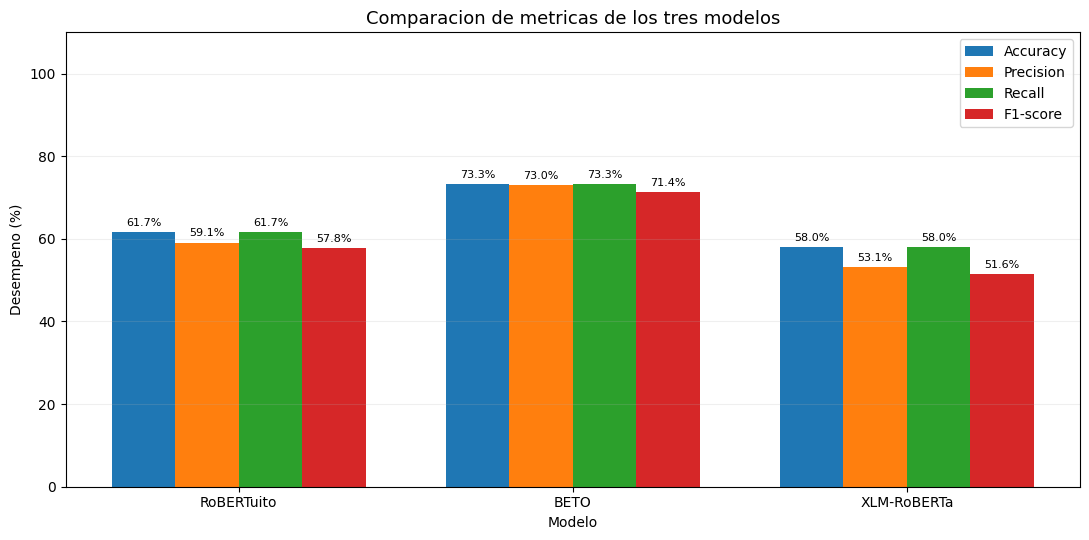


Matrices de confusión


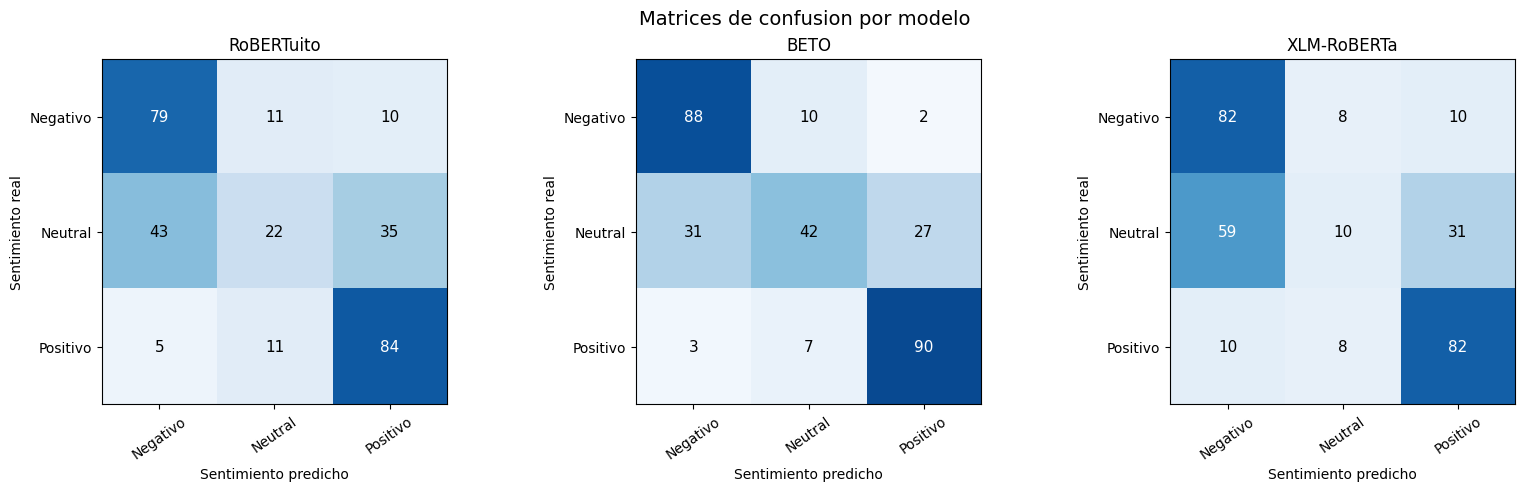


Gráfico F1-Score por sentimiento


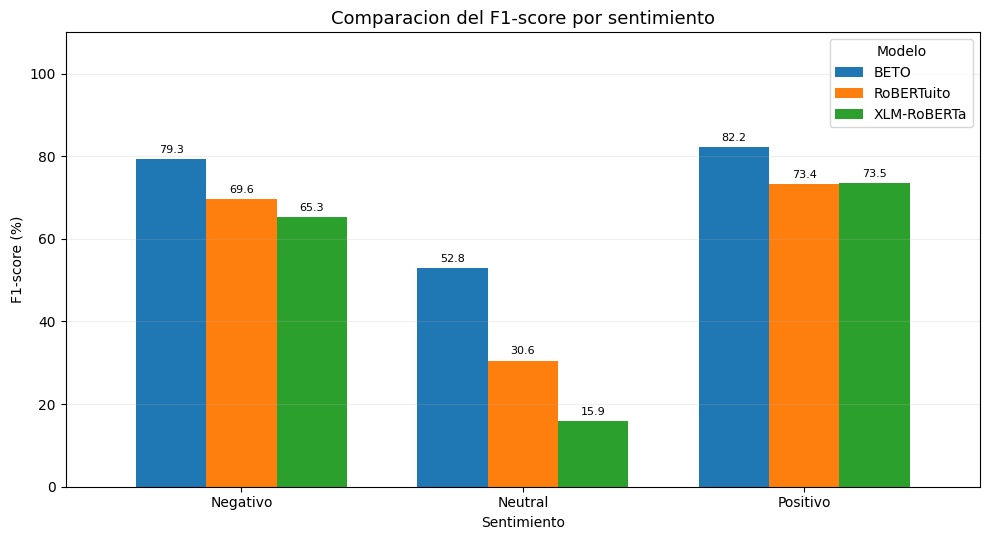


Resúmen de evaluación
Modelo con mayor F1-score macro: BETO
F1-score macro: 0.7143
Modelo con mayor accuracy: BETO

Graficos generados:
- grafico_metricas_generales.png
- matrices_confusion.png
- grafico_f1_por_sentimiento.png

Evaluacion de metricas finalizada correctamente.
La seleccion definitiva del modelo requiere considerar tambien la latencia y el caso de uso.


In [8]:
# TAREA 4
# Actividad 1.
# Cálculo de métricas de evaluación
# Accuracy, Precision, Recall y F1-score

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("=" * 65)
print("CELDA 3. EVALUACION DEL DESEMPENO DE LOS MODELOS")
print("=" * 65)

# Preparación y validación de los resultados.
# Se utilizan las predicciones generadas en la celda 2.
# Las etiquetas NEG, NEU y POS representan los sentimientos.
categorias = ["NEG", "NEU", "POS"]
nombres_categorias = ["Negativo", "Neutral", "Positivo"]

# Diccionarios para conservar las metricas y matrices.
metricas_modelos = {}
metricas_por_clase = {}
matrices_confusion = {}

# Verificación de la existencia de las predicciones de los tres modelos.
if len(predicciones_modelos) != 3:
    raise ValueError(
        "Se requieren las predicciones de los tres modelos."
    )

# Cálculo de métricas generales
for nombre, tabla in predicciones_modelos.items():

    # Se Recuperan los sentimientos reales y los predichos.
    reales = tabla["sentimiento_real"].tolist()
    predichos = tabla["sentimiento_predicho"].tolist()

    # Comprobación de que existan 300 predicciones validas.
    if len(reales) != 300 or len(predichos) != 300:
        raise ValueError(
            f"Cantidad de registros incorrecta en {nombre}."
        )

    if not (
        set(reales).issubset(categorias)
        and set(predichos).issubset(categorias)
    ):
        raise ValueError(
            f"Se encontraron etiquetas invalidas en {nombre}."
        )

    # Accuracy: proporcion de clasificaciones correctas.
    accuracy = accuracy_score(reales, predichos)

    # Precision macro: promedio de precision por categoria.
    precision = precision_score(
        reales, predichos,
        labels=categorias,
        average="macro",
        zero_division=0
    )

    # Recall macro: promedio de recuperacion por categoria.
    recall = recall_score(
        reales, predichos,
        labels=categorias,
        average="macro",
        zero_division=0
    )

    # F1 macro: promedio del F1-score de cada categoria.
    f1 = f1_score(
        reales, predichos,
        labels=categorias,
        average="macro",
        zero_division=0
    )

    # Se guardan las cuatro metricas de cada modelo.
    metricas_modelos[nombre] = {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1
    }

    # Cálculo de las métricas por sentimiento.
    reporte = classification_report(
        reales,
        predichos,
        labels=categorias,
        output_dict=True,
        zero_division=0
    )

    metricas_por_clase[nombre] = reporte

    # La matriz de confusión permite identificar errores.
    matrices_confusion[nombre] = confusion_matrix(
        reales,
        predichos,
        labels=categorias
    )

# Organización de los resultados generales en una tabla.
df_metricas = pd.DataFrame.from_dict(
    metricas_modelos,
    orient="index"
)

df_metricas.index.name = "Modelo"

print("\nResultados Generales (escala de 0 a 1)")
display(df_metricas.round(4))

print("\nResultados Expresados En Porcentaje")
display((df_metricas * 100).round(2))

# Métricas detalladas por sentimiento
print("\n" + "=" * 65)
print("Métricas Por Categoría De Sentimiento")
print("=" * 65)

for nombre, reporte in metricas_por_clase.items():

    print(f"\nModelo: {nombre}")

    filas = []

    for codigo, sentimiento in zip(
        categorias, nombres_categorias
    ):
        filas.append({
            "Sentimiento": sentimiento,
            "Precision": reporte[codigo]["precision"],
            "Recall": reporte[codigo]["recall"],
            "F1-score": reporte[codigo]["f1-score"],
            "Registros": reporte[codigo]["support"]
        })

    df_detalle = pd.DataFrame(filas)

    display(
        df_detalle.round(4)
    )

# Gráfico comparativo de métricas generales
print("\nGráfico comparativo de métricas generales")

fig, ax = plt.subplots(figsize=(11, 5.5))

# Cada grupo de barras representa un modelo.
posiciones = np.arange(len(df_metricas.index))
ancho = 0.19

for i, metrica in enumerate(df_metricas.columns):

    valores = df_metricas[metrica].values * 100

    barras = ax.bar(
        posiciones + (i - 1.5) * ancho,
        valores,
        width=ancho,
        label=metrica
    )

    # Mostramos el porcentaje encima de cada barra.
    for barra, valor in zip(barras, valores):
        ax.text(
            barra.get_x() + barra.get_width() / 2,
            barra.get_height() + 1,
            f"{valor:.1f}%",
            ha="center",
            va="bottom",
            fontsize=8
        )

ax.set_title(
    "Comparacion de metricas de los tres modelos",
    fontsize=13
)
ax.set_ylabel("Desempeno (%)")
ax.set_xlabel("Modelo")
ax.set_xticks(posiciones)
ax.set_xticklabels(df_metricas.index)
ax.set_ylim(0, 110)
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.savefig(
    "/content/grafico_metricas_generales.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# Matrices de confusión
print("\nMatrices de confusión")

# Filas: sentimiento real.
# Columnas: sentimiento predicho.
# La diagonal indica clasificaciones correctas.
fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 4.8),
    constrained_layout=True
)

for ax, (nombre, matriz) in zip(
    axes, matrices_confusion.items()
):

    imagen = ax.imshow(
        matriz,
        cmap="Blues",
        vmin=0,
        vmax=100
    )

    ax.set_title(nombre)
    ax.set_xticks(range(3))
    ax.set_yticks(range(3))
    ax.set_xticklabels(nombres_categorias, rotation=35)
    ax.set_yticklabels(nombres_categorias)
    ax.set_xlabel("Sentimiento predicho")
    ax.set_ylabel("Sentimiento real")

    # Se muestra la cantidad de opiniones por celda.
    for i in range(3):
        for j in range(3):
            valor = matriz[i, j]

            ax.text(
                j, i, str(valor),
                ha="center",
                va="center",
                color=(
                    "white" if valor > 50 else "black"
                ),
                fontsize=11
            )

fig.suptitle(
    "Matrices de confusion por modelo",
    fontsize=14
)

plt.savefig(
    "/content/matrices_confusion.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# Gráfico F1-Score por sentimiento
print("\nGráfico F1-Score por sentimiento")

datos_f1 = []

for nombre, reporte in metricas_por_clase.items():

    for codigo, sentimiento in zip(
        categorias, nombres_categorias
    ):
        datos_f1.append({
            "Modelo": nombre,
            "Sentimiento": sentimiento,
            "F1-score": reporte[codigo]["f1-score"] * 100
        })

df_f1_clases = pd.DataFrame(datos_f1)

tabla_f1 = df_f1_clases.pivot(
    index="Sentimiento",
    columns="Modelo",
    values="F1-score"
).reindex(nombres_categorias)

ax = tabla_f1.plot(
    kind="bar",
    figsize=(10, 5.5),
    width=0.75
)

ax.set_title(
    "Comparacion del F1-score por sentimiento",
    fontsize=13
)
ax.set_ylabel("F1-score (%)")
ax.set_xlabel("Sentimiento")
ax.set_ylim(0, 110)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Modelo")
ax.grid(axis="y", alpha=0.2)

for contenedor in ax.containers:
    ax.bar_label(
        contenedor,
        fmt="%.1f",
        padding=3,
        fontsize=8
    )

plt.tight_layout()
plt.savefig(
    "/content/grafico_f1_por_sentimiento.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# Resúmen de evaluación
print("\n" + "=" * 65)
print("Resúmen de evaluación")
print("=" * 65)

# Identificamos el modelo con mayor F1 macro.
mejor_f1 = df_metricas["F1-score"].idxmax()
valor_f1 = df_metricas.loc[mejor_f1, "F1-score"]

# Identificamos el modelo con mayor accuracy.
mejor_accuracy = df_metricas["Accuracy"].idxmax()

print(f"Modelo con mayor F1-score macro: {mejor_f1}")
print(f"F1-score macro: {valor_f1:.4f}")
print(f"Modelo con mayor accuracy: {mejor_accuracy}")

print("\nGraficos generados:")
print("- grafico_metricas_generales.png")
print("- matrices_confusion.png")
print("- grafico_f1_por_sentimiento.png")

print("\nEvaluacion de metricas finalizada correctamente.")
print(
    "La seleccion definitiva del modelo requiere "
    "considerar tambien la latencia y el caso de uso."
)


Device set to use cuda:0


CELDA 4. MEDICION DE LATENCIA
GPU utilizada: Tesla T4
Opiniones por ejecucion: 300
Mediciones por modelo: 5
Tamano de lote: 16

Evaluando latencia de: RoBERTuito
Ejecucion 1: 1.602 segundos | 5.340 ms/opinion
Ejecucion 2: 1.585 segundos | 5.284 ms/opinion
Ejecucion 3: 1.589 segundos | 5.296 ms/opinion
Ejecucion 4: 1.596 segundos | 5.321 ms/opinion
Ejecucion 5: 1.608 segundos | 5.361 ms/opinion


Device set to use cuda:0



Evaluando latencia de: BETO
Ejecucion 1: 1.841 segundos | 6.136 ms/opinion
Ejecucion 2: 1.819 segundos | 6.063 ms/opinion
Ejecucion 3: 1.843 segundos | 6.145 ms/opinion
Ejecucion 4: 1.856 segundos | 6.187 ms/opinion
Ejecucion 5: 1.843 segundos | 6.142 ms/opinion


Device set to use cuda:0



Evaluando latencia de: XLM-RoBERTa
Ejecucion 1: 1.788 segundos | 5.959 ms/opinion
Ejecucion 2: 1.748 segundos | 5.828 ms/opinion
Ejecucion 3: 1.752 segundos | 5.841 ms/opinion
Ejecucion 4: 1.734 segundos | 5.779 ms/opinion
Ejecucion 5: 1.736 segundos | 5.786 ms/opinion

Resultados Generales De Latencia


,Tiempo_promedio_s,Desviacion_s,Latencia_promedio_ms,Tiempo_minimo_s,Tiempo_maximo_s,Opiniones_por_segundo
Modelo,,,,,,
RoBERTuito,1.5962,0.0094,5.3206,1.5853,1.6083,187.9496
XLM-RoBERTa,1.7516,0.0217,5.8386,1.7338,1.7878,171.2744
BETO,1.8403,0.0134,6.1344,1.8188,1.8560,163.0152



Tiempos Individuales De Las Cinco Ejecuciones


Modelo,BETO,RoBERTuito,XLM-RoBERTa
Ejecucion,,,
1,1.8407,1.6019,1.7878
2,1.8188,1.5853,1.7484
3,1.8435,1.5889,1.7522
4,1.8560,1.5964,1.7338
5,1.8426,1.6083,1.7357



Gráfico de tiempo promedio


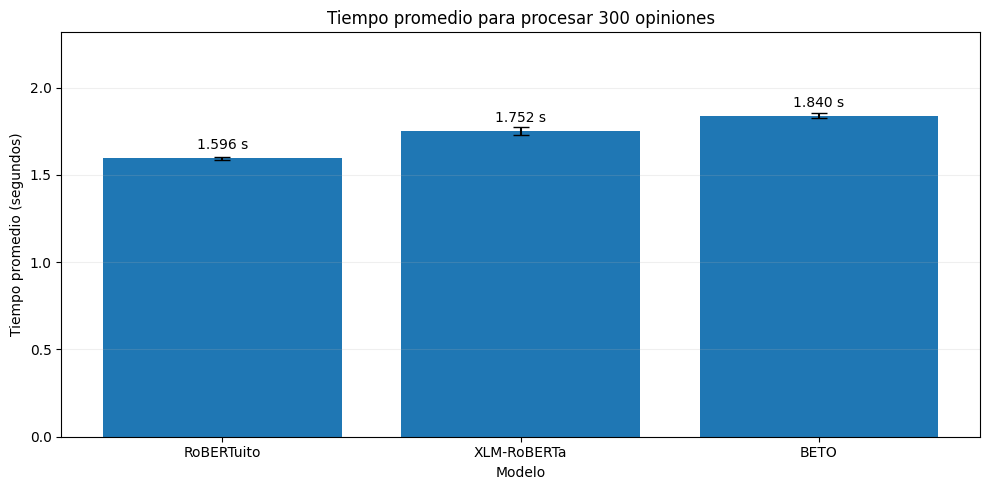


Gráfico de latencia por opinión


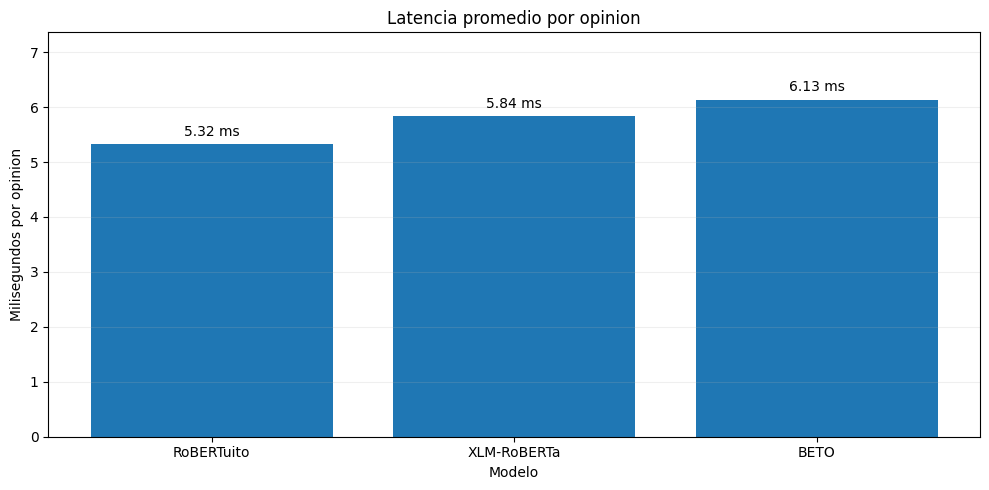


Gráfico de variación entre ejecuciones


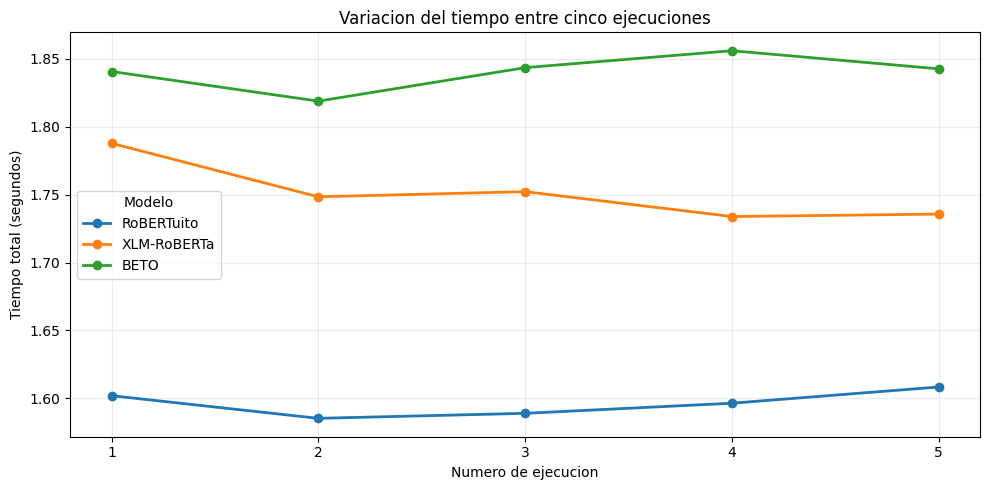


RESUMEN DE LA MEDICION DE LATENCIA
Modelo con menor tiempo promedio: RoBERTuito
Tiempo promedio: 1.5962 segundos
Modelo con mayor tiempo promedio: BETO
Diferencia entre el mas rapido y el mas lento: 13.27%

Graficos generados:
- grafico_tiempo_promedio.png
- grafico_latencia_por_opinion.png
- grafico_variacion_latencia.png

Medicion de latencia finalizada correctamente.
La seleccion definitiva del modelo debe considerar tanto las metricas predictivas como la eficiencia.


In [9]:
# TAREA 4
# Actividad 1.
# Medición de latencia
# Comparacion de eficiencia de tres modelos preentrenados

import time
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from transformers import pipeline

print("=" * 65)
print("CELDA 4. MEDICION DE LATENCIA")
print("=" * 65)

# Se emplean las mismas opiniones y condiciones de la celda 2.
textos = df_evaluacion["comentario"].fillna("").astype(str).tolist()

numero_ejecuciones = 5
tamano_lote = 16
longitud_maxima = 128

# Confirmación de que PyTorch puede utilizar la GPU.
if not torch.cuda.is_available():
    raise RuntimeError(
        "No se detecto una GPU disponible para el experimento."
    )

if len(textos) != 300:
    raise ValueError(
        "Se esperaban 300 opiniones para la evaluacion."
    )

# Almacenamiento de los tiempos individuales de cada modelo.
resultados_latencia = []

print(f"GPU utilizada: {torch.cuda.get_device_name(0)}")
print(f"Opiniones por ejecucion: {len(textos)}")
print(f"Mediciones por modelo: {numero_ejecuciones}")
print(f"Tamano de lote: {tamano_lote}")

# Medición de tiempos de inferencia
# Ejecutamos los modelos secuencialmente para evitar
# que compitan por la memoria de la GPU.
for nombre, modelo in modelos_cargados.items():

    print(f"\nEvaluando latencia de: {nombre}")

    tokenizador = tokenizadores[nombre]

    # Configuración del pipeline con la GPU disponible.
    clasificador = pipeline(
        task="text-classification",
        model=modelo,
        tokenizer=tokenizador,
        device=0
    )

    # Ejecución del modelo sin actualizar sus parametros.
    modelo.eval()

    # Calentamiento: Preparación del modelo antes de medir.
    # Esto reduce la influencia de la inicializacion.
    for _ in range(2):
        _ = clasificador(
            textos,
            batch_size=tamano_lote,
            truncation=True,
            max_length=longitud_maxima
        )

    torch.cuda.synchronize()

    # Realización de cinco mediciones independientes.
    for ejecucion in range(1, numero_ejecuciones + 1):

        torch.cuda.synchronize()
        inicio = time.perf_counter()

        predicciones = clasificador(
            textos,
            batch_size=tamano_lote,
            truncation=True,
            max_length=longitud_maxima
        )

        # Espera a que la GPU termine sus operaciones.
        torch.cuda.synchronize()
        tiempo_total = time.perf_counter() - inicio

        # Comprobación de que se procesaron todas las opiniones.
        if len(predicciones) != len(textos):
            raise ValueError(
                f"Cantidad incorrecta de predicciones: {nombre}"
            )

        # Cálculo de indicadores de eficiencia.
        latencia_ms = (tiempo_total / len(textos)) * 1000
        opiniones_segundo = len(textos) / tiempo_total

        resultados_latencia.append({
            "Modelo": nombre,
            "Ejecucion": ejecucion,
            "Tiempo_total_s": tiempo_total,
            "Latencia_promedio_ms": latencia_ms,
            "Opiniones_por_segundo": opiniones_segundo
        })

        print(
            f"Ejecucion {ejecucion}: "
            f"{tiempo_total:.3f} segundos | "
            f"{latencia_ms:.3f} ms/opinion"
        )

    # Liberación de memoria GPU antes del siguiente modelo.
    del clasificador
    modelo.to("cpu")
    gc.collect()
    torch.cuda.empty_cache()

# Cálculo de resultados estadísticos
df_latencia = pd.DataFrame(resultados_latencia)

# Cálculo del promedio y variabilidad por modelo.
# El rendimiento se obtiene a partir del tiempo promedio.
resumen_latencia = df_latencia.groupby(
    "Modelo"
).agg(
    Tiempo_promedio_s=("Tiempo_total_s", "mean"),
    Desviacion_s=("Tiempo_total_s", "std"),
    Latencia_promedio_ms=("Latencia_promedio_ms", "mean"),
    Tiempo_minimo_s=("Tiempo_total_s", "min"),
    Tiempo_maximo_s=("Tiempo_total_s", "max")
)

resumen_latencia["Opiniones_por_segundo"] = (
    len(textos) / resumen_latencia["Tiempo_promedio_s"]
)

# Se ordena el modelo más rápido al más lento.
resumen_latencia = resumen_latencia.sort_values(
    "Tiempo_promedio_s"
)

print("\n" + "=" * 65)
print("Resultados Generales De Latencia")
print("=" * 65)

display(resumen_latencia.round(4))

print("\nTiempos Individuales De Las Cinco Ejecuciones")
display(
    df_latencia.pivot(
        index="Ejecucion",
        columns="Modelo",
        values="Tiempo_total_s"
    ).round(4)
)

# Gráfico de tiempo promedio
print("\nGráfico de tiempo promedio")

fig, ax = plt.subplots(figsize=(10, 5))

modelos = resumen_latencia.index.tolist()
tiempos = resumen_latencia["Tiempo_promedio_s"].values
desviaciones = resumen_latencia["Desviacion_s"].values

barras = ax.bar(
    modelos,
    tiempos,
    yerr=desviaciones,
    capsize=6
)

# Se indica el tiempo promedio encima de cada barra.
for barra, valor in zip(barras, tiempos):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + max(desviaciones) + 0.03,
        f"{valor:.3f} s",
        ha="center",
        fontsize=10
    )

ax.set_title(
    "Tiempo promedio para procesar 300 opiniones"
)
ax.set_ylabel("Tiempo promedio (segundos)")
ax.set_xlabel("Modelo")
ax.set_ylim(
    0,
    max(tiempos + desviaciones) * 1.25
)
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.savefig(
    "/content/grafico_tiempo_promedio.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# Gráfico de latencia por opinión
print("\nGráfico de latencia por opinión")

fig, ax = plt.subplots(figsize=(10, 5))

latencias = resumen_latencia["Latencia_promedio_ms"].values

barras = ax.bar(
    modelos,
    latencias
)

for barra, valor in zip(barras, latencias):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + max(latencias) * 0.025,
        f"{valor:.2f} ms",
        ha="center",
        fontsize=10
    )

ax.set_title(
    "Latencia promedio por opinion"
)
ax.set_ylabel("Milisegundos por opinion")
ax.set_xlabel("Modelo")
ax.set_ylim(0, max(latencias) * 1.2)
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.savefig(
    "/content/grafico_latencia_por_opinion.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# Gráfico de variación entre ejecuciones
print("\nGráfico de variación entre ejecuciones")

fig, ax = plt.subplots(figsize=(10, 5))

# Una linea por modelo permite observar su estabilidad.
for nombre in modelos:

    datos = df_latencia[
        df_latencia["Modelo"] == nombre
    ].sort_values("Ejecucion")

    ax.plot(
        datos["Ejecucion"],
        datos["Tiempo_total_s"],
        marker="o",
        linewidth=2,
        label=nombre
    )

ax.set_title(
    "Variacion del tiempo entre cinco ejecuciones"
)
ax.set_xlabel("Numero de ejecucion")
ax.set_ylabel("Tiempo total (segundos)")
ax.set_xticks(range(1, numero_ejecuciones + 1))
ax.legend(title="Modelo")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.savefig(
    "/content/grafico_variacion_latencia.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# Resúmen de resultados
print("\n" + "=" * 65)
print("RESUMEN DE LA MEDICION DE LATENCIA")
print("=" * 65)

modelo_rapido = resumen_latencia.index[0]
tiempo_rapido = resumen_latencia.iloc[0][
    "Tiempo_promedio_s"
]

modelo_lento = resumen_latencia.index[-1]
tiempo_lento = resumen_latencia.iloc[-1][
    "Tiempo_promedio_s"
]

diferencia_porcentual = (
    (tiempo_lento - tiempo_rapido) / tiempo_lento
) * 100

print(f"Modelo con menor tiempo promedio: {modelo_rapido}")
print(f"Tiempo promedio: {tiempo_rapido:.4f} segundos")
print(f"Modelo con mayor tiempo promedio: {modelo_lento}")

print(
    f"Diferencia entre el mas rapido y el mas lento: "
    f"{diferencia_porcentual:.2f}%"
)

print("\nGraficos generados:")
print("- grafico_tiempo_promedio.png")
print("- grafico_latencia_por_opinion.png")
print("- grafico_variacion_latencia.png")

# Exportación de los resultados para su documentacion.
df_latencia.to_csv(
    "/content/resultados_latencia_detalle.csv",
    index=False
)

resumen_latencia.to_csv(
    "/content/resultados_latencia_resumen.csv"
)

print("\nMedicion de latencia finalizada correctamente.")
print(
    "La seleccion definitiva del modelo debe considerar "
    "tanto las metricas predictivas como la eficiencia."
)

CELDA 5. CONSOLIDACION DE RESULTADOS

Tabla Ejecutiva De Resultados


,Accuracy (%),Precision macro (%),Recall macro (%),F1-score macro (%),Tiempo promedio (s),Latencia (ms/opinion),Opiniones/segundo
Modelo,,,,,,,
BETO,73.33,72.98,73.33,71.43,1.84,6.13,163.02
RoBERTuito,61.67,59.11,61.67,57.84,1.60,5.32,187.95
XLM-RoBERTa,58.00,53.14,58.00,51.58,1.75,5.84,171.27



Gráfico de precisión frente a eficiencia


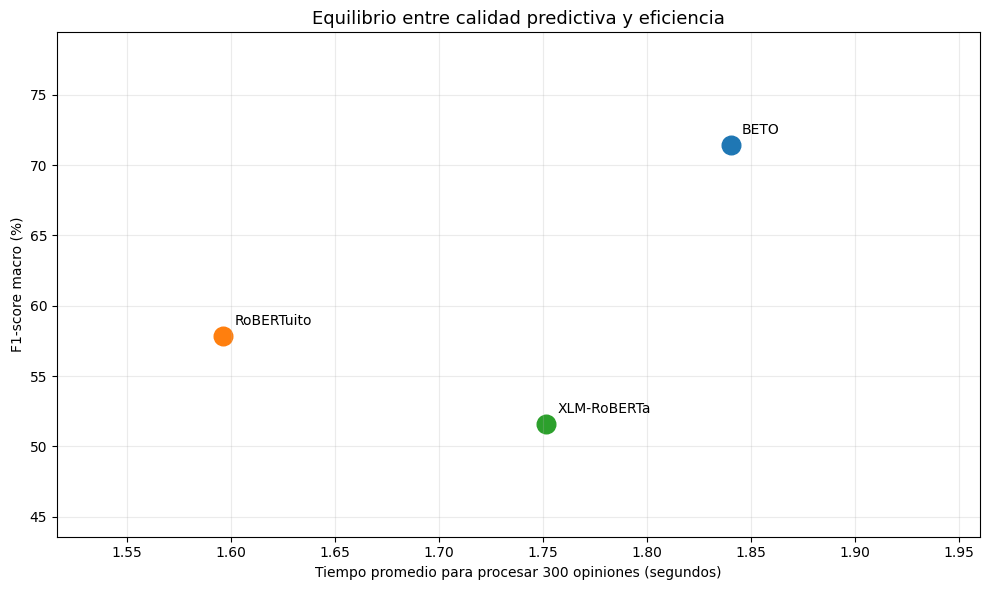


Resúmen Ejecutivo De La Comparación
Mayor F1-score macro: BETO (71.43%)
Mayor accuracy: BETO
Menor tiempo promedio: RoBERTuito (1.5962 segundos)
Diferencia de F1-score entre ambos modelos: 13.59 puntos porcentuales
Tiempo adicional del modelo con mejor F1: 15.30%

ARCHIVOS GENERADOS:
- comparacion_final_modelos.csv
- grafico_equilibrio_precision_eficiencia.png

Consolidacion de resultados finalizada correctamente.
La seleccion definitiva del modelo se justificara considerando el contexto y los objetivos del proyecto.


In [11]:
# TAREA 4
# Actividad 1.
# Consolidación de resultados
# Comparación de calidad predictiva y eficiencia

import pandas as pd
import matplotlib.pyplot as plt

print("=" * 65)
print("CELDA 5. CONSOLIDACION DE RESULTADOS")
print("=" * 65)

# Integración de resultados
# Recuperación de las metricas calculadas en la celda 3.
# Los valores se convierten de escala 0-1 a porcentaje.
tabla_metricas = df_metricas.copy() * 100

# Recuperación de los tiempos promedio de la celda 4.
tabla_latencia = resumen_latencia[
    [
        "Tiempo_promedio_s",
        "Latencia_promedio_ms",
        "Opiniones_por_segundo"
    ]
].copy()

# Unificación los resultados mediante el nombre del modelo.
# El indice de ambas tablas corresponde a cada modelo.
tabla_consolidada = tabla_metricas.join(
    tabla_latencia,
    how="inner"
)

# Verificación de que se hayan integrado los tres modelos.
if len(tabla_consolidada) != 3:
    raise ValueError(
        "No se integraron correctamente los tres modelos."
    )

# Asignación de nombres comprensibles a las columnas.
tabla_consolidada = tabla_consolidada.rename(
    columns={
        "Accuracy": "Accuracy (%)",
        "Precision": "Precision macro (%)",
        "Recall": "Recall macro (%)",
        "F1-score": "F1-score macro (%)",
        "Tiempo_promedio_s": "Tiempo promedio (s)",
        "Latencia_promedio_ms": "Latencia (ms/opinion)",
        "Opiniones_por_segundo": "Opiniones/segundo"
    }
)

# Ordenamento de los modelos de mayor a menor F1-score.
tabla_consolidada = tabla_consolidada.sort_values(
    "F1-score macro (%)",
    ascending=False
)

print("\nTabla Ejecutiva De Resultados")
display(tabla_consolidada.round(2))

# Gráfico de precisión frente a eficiencia
print("\nGráfico de precisión frente a eficiencia")

fig, ax = plt.subplots(figsize=(10, 6))

# Eje horizontal: tiempo promedio para 300 opiniones.
# Eje vertical: F1-score macro.
# La posicion ideal se encuentra arriba y a la izquierda.
for nombre, fila in tabla_consolidada.iterrows():

    tiempo = fila["Tiempo promedio (s)"]
    f1 = fila["F1-score macro (%)"]

    ax.scatter(
        tiempo,
        f1,
        s=180,
        label=nombre
    )

    # Se identifica cada punto con el nombre del modelo.
    ax.annotate(
        nombre,
        (tiempo, f1),
        xytext=(8, 8),
        textcoords="offset points",
        fontsize=10
    )

ax.set_title(
    "Equilibrio entre calidad predictiva y eficiencia",
    fontsize=13
)

ax.set_xlabel(
    "Tiempo promedio para procesar 300 opiniones (segundos)"
)
ax.set_ylabel("F1-score macro (%)")

ax.grid(alpha=0.25)

# Ajuste de los limites para visualizar mejor las diferencias.
tiempos = tabla_consolidada["Tiempo promedio (s)"]
valores_f1 = tabla_consolidada["F1-score macro (%)"]

ax.set_xlim(
    tiempos.min() - 0.08,
    tiempos.max() + 0.12
)
ax.set_ylim(
    max(0, valores_f1.min() - 8),
    min(100, valores_f1.max() + 8)
)

plt.tight_layout()

plt.savefig(
    "/content/grafico_equilibrio_precision_eficiencia.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# Resúmen Automático
print("\n" + "=" * 65)
print("Resúmen Ejecutivo De La Comparación")
print("=" * 65)

# Se identifica el modelo con mayor F1-score macro.
modelo_mejor_f1 = tabla_consolidada[
    "F1-score macro (%)"
].idxmax()

valor_mejor_f1 = tabla_consolidada.loc[
    modelo_mejor_f1,
    "F1-score macro (%)"
]

# Se identifica el el modelo con mayor accuracy.
modelo_mejor_accuracy = tabla_consolidada[
    "Accuracy (%)"
].idxmax()

# Se identifica el modelo con menor tiempo promedio.
modelo_mas_rapido = tabla_consolidada[
    "Tiempo promedio (s)"
].idxmin()

tiempo_mas_rapido = tabla_consolidada.loc[
    modelo_mas_rapido,
    "Tiempo promedio (s)"
]

print(
    f"Mayor F1-score macro: {modelo_mejor_f1} "
    f"({valor_mejor_f1:.2f}%)"
)

print(
    f"Mayor accuracy: {modelo_mejor_accuracy}"
)

print(
    f"Menor tiempo promedio: {modelo_mas_rapido} "
    f"({tiempo_mas_rapido:.4f} segundos)"
)

# Cálculo de la diferencia de F1-score entre el modelo
# con mayor F1 y el modelo con menor tiempo de inferencia.
diferencia_f1 = (
    tabla_consolidada.loc[
        modelo_mejor_f1, "F1-score macro (%)"
    ]
    -
    tabla_consolidada.loc[
        modelo_mas_rapido, "F1-score macro (%)"
    ]
)

print(
    f"Diferencia de F1-score entre ambos modelos: "
    f"{diferencia_f1:.2f} puntos porcentuales"
)

# Cálculo cuanto mas tiempo requiere el modelo
# con mejor F1 respecto al modelo mas rapido.
tiempo_mejor_f1 = tabla_consolidada.loc[
    modelo_mejor_f1, "Tiempo promedio (s)"
]

incremento_tiempo = (
    (tiempo_mejor_f1 - tiempo_mas_rapido)
    / tiempo_mas_rapido
) * 100

print(
    f"Tiempo adicional del modelo con mejor F1: "
    f"{incremento_tiempo:.2f}%"
)

# Exportación de resultados
# Se guarda la tabla para documentacion y reproducibilidad.
ruta_resultados = "/content/comparacion_final_modelos.csv"

tabla_consolidada.to_csv(
    ruta_resultados,
    encoding="utf-8-sig"
)

print("\nARCHIVOS GENERADOS:")
print("- comparacion_final_modelos.csv")
print("- grafico_equilibrio_precision_eficiencia.png")

print("\nConsolidacion de resultados finalizada correctamente.")
print(
    "La seleccion definitiva del modelo se justificara "
    "considerando el contexto y los objetivos del proyecto."
)